# Globepay acceptance: data exploration and charts

In [ ]:
import json, pathlib
from math import sqrt, erf
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

ROOT = pathlib.Path('..') if pathlib.Path('../data').exists() else pathlib.Path('.')
FIG = ROOT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

# Near-monochrome on purpose: grey = context, black = emphasis. Colour can be added wherever the charts are used.
GREY, DARK, INK2, MUTED, GRID = '#a8a7a0', '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': .6, 'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'figure.dpi': 110,
    'savefig.dpi': 200, 'savefig.bbox': 'tight'})
PCT = mt.PercentFormatter(1.0, decimals=0)
USD_M = mt.FuncFormatter(lambda v, _: f'${v:,.0f}M')

def save(name):
    plt.savefig(FIG / f'{name}.png'); plt.show()

def label_bars(ax, bars, fmt, horizontal=False, pad=0, **kw):
    """Write each bar's value next to (or inside) its end."""
    style = dict(fontsize=8, color=INK2) | kw
    for b in bars:
        if horizontal:
            v = b.get_width()
            ax.text(v + pad, b.get_y() + b.get_height() / 2, fmt(v), va='center', **style)
        else:
            v = b.get_height()
            ax.text(b.get_x() + b.get_width() / 2, v + pad, fmt(v), ha='center', **style)

def ztest(a, b):
    """Two-proportion z-test on boolean series. Returns (diff, p-value)."""
    p = (a.sum() + b.sum()) / (len(a) + len(b))
    z = (a.mean() - b.mean()) / sqrt(p * (1 - p) * (1 / len(a) + 1 / len(b)))
    return a.mean() - b.mean(), 2 * (1 - .5 * (1 + erf(abs(z) / sqrt(2))))

## 1. Load and clean

In [ ]:
acc = pd.read_csv(ROOT / 'data/raw/acceptance_report.csv', sep=';', parse_dates=['date_time'])
cb = pd.read_csv(ROOT / 'data/raw/chargeback_report.csv')

# Defensive cleaning (same rules as sql/00_setup.sql): TRIM spaces, UPPER case on codes.
# external_ref is only trimmed: IDs are case-sensitive.
for col in ['state', 'country', 'currency']:
    acc[col] = acc[col].str.strip().str.upper()
acc['external_ref'] = acc['external_ref'].str.strip()
cb['external_ref'] = cb['external_ref'].str.strip()

acc['date_time'] = acc['date_time'].dt.tz_convert('UTC').dt.tz_localize(None)   # values end in 'Z' (UTC)
acc['fx'] = [json.loads(r).get(c) for r, c in zip(acc['rates'], acc['currency'])]   # .get: NaN, not a crash
acc['amount_usd'] = acc['amount'] / acc['fx']
acc['accepted'] = acc['state'].eq('ACCEPTED')
acc['declined_usd'] = acc['amount_usd'].where(~acc['accepted'], 0)
acc['month'] = acc['date_time'].dt.to_period('M').dt.to_timestamp()
acc['week'] = acc['date_time'].dt.to_period('W').dt.start_time

dec = acc[~acc['accepted']]
overall = acc['accepted'].mean()

# Fail loudly if the data breaks an assumption, instead of producing a silently wrong number
unexpected = set(acc['state'].dropna()) - {'ACCEPTED', 'DECLINED'}
assert acc['state'].notna().all() and not unexpected, f'Unexpected state values: {unexpected}'
assert acc['fx'].notna().all(), f"No FX rate for: {acc.loc[acc['fx'].isna(), 'currency'].unique()}"
assert acc['external_ref'].is_unique and cb['external_ref'].is_unique, 'Duplicate external_ref'
print(acc.shape, cb.shape, '| checks passed: state values, FX found, unique external_ref')
acc.head()

(5430, 17) (5430, 4) | checks passed: state values, FX found, unique external_ref


,external_ref,status,source,ref,date_time,state,cvv_provided,amount,country,currency,rates,fx,amount_usd,accepted,declined_usd,month,week
0,nCyEIIGaP5QQ2Wqb-_Rt8,True,GLOBALPAY,evt_1ESgcCOV7fY1ChY1MkZizZt,2019-01-01 00:00:00,DECLINED,False,1020.46,US,USD,"{""CAD"":1.415,""EUR"":0.926,""MXN"":25.103,""USD"":1,...",1.0,1020.46,False,1020.46,2019-01-01,2018-12-31
1,ptNiI9B7NNpK7VsMZx6zZ,True,GLOBALPAY,evt_1EBMGCEjEtianKMJaZXOx1y,2019-01-01 04:48:00,ACCEPTED,False,1582.57,US,USD,"{""CAD"":1.415,""EUR"":0.926,""MXN"":25.103,""USD"":1,...",1.0,1582.57,True,0.00,2019-01-01,2018-12-31
2,1GS5BDKBnauCt-3nHPs6x,True,GLOBALPAY,evt_1EOALu0AZqEhZBn9ub_nbcE,2019-01-01 09:36:00,DECLINED,False,1653.07,US,USD,"{""CAD"":1.415,""EUR"":0.926,""MXN"":25.103,""USD"":1,...",1.0,1653.07,False,1653.07,2019-01-01,2018-12-31
3,Y_oecYz8GjBDaxmMqkkLQ,True,GLOBALPAY,evt_1ESHsWyaSPqE1mrmJ2B6rvs,2019-01-01 14:24:00,ACCEPTED,False,2228.17,US,USD,"{""CAD"":1.415,""EUR"":0.926,""MXN"":25.103,""USD"":1,...",1.0,2228.17,True,0.00,2019-01-01,2018-12-31
4,LlEs1TnKVa2xX6PH9Zsz0,True,GLOBALPAY,evt_1EjzPk13qLzmvDR_4hXuMMw,2019-01-01 19:12:00,ACCEPTED,False,2589.92,US,USD,"{""CAD"":1.415,""EUR"":0.926,""MXN"":25.103,""USD"":1,...",1.0,2589.92,True,0.00,2019-01-01,2018-12-31


## 2. Data quality checks

In [ ]:
checks = {
    'rows (acceptance / chargeback)': (len(acc), len(cb)),
    'unique external_ref (acceptance / chargeback)': (acc.external_ref.nunique(), cb.external_ref.nunique()),
    'refs in acceptance not in chargeback': len(set(acc.external_ref) - set(cb.external_ref)),
    'refs in chargeback not in acceptance': len(set(cb.external_ref) - set(acc.external_ref)),
    'null cells (acceptance)': int(acc.isna().sum().sum()),
    'date range': (str(acc.date_time.min()), str(acc.date_time.max())),
    'non-positive amounts': int((acc.amount <= 0).sum()),
    'distinct rates snapshots': acc.rates.nunique(),
    'status / source values': (acc.status.unique().tolist(), acc.source.unique().tolist()),
}
for k, v in checks.items():
    print(f'{k:48s} {v}')
acc.groupby('country').agg(currency=('currency', 'first'), transactions=('currency', 'size')).T

rows (acceptance / chargeback)                   (5430, 5430)
unique external_ref (acceptance / chargeback)    (5430, 5430)
refs in acceptance not in chargeback             0
refs in chargeback not in acceptance             0
null cells (acceptance)                          0
date range                                       ('2019-01-01 00:00:00', '2019-06-30 19:12:00')
non-positive amounts                             1
distinct rates snapshots                         1086
status / source values                           ([True], ['GLOBALPAY'])


country,AE,CA,FR,MX,UK,US
currency,USD,CAD,EUR,MXN,GBP,USD
transactions,905,905,905,905,905,905


## 3. Volume of declined payments in USD

In [ ]:
print(f'Declined transactions: {len(dec):,} of {len(acc):,} ({len(dec)/len(acc):.1%})')
print(f'Declined volume:       ${dec.amount_usd.sum()/1e6:,.1f}M of ${acc.amount_usd.sum()/1e6:,.1f}M processed')
m = acc.groupby('month').agg(txns=('accepted', 'size'), declined_n=('declined_usd', lambda s: (s > 0).sum()),
                             acc_rate=('accepted', 'mean'), total_usd=('amount_usd', 'sum'),
                             declined_usd=('declined_usd', 'sum'))
m.round(3)

Declined transactions: 1,671 of 5,430 (30.8%)
Declined volume:       $132.7M of $430.3M processed


,txns,declined_n,acc_rate,total_usd,declined_usd
month,,,,,
2019-01-01,930,283,0.696,1.241517e+07,3.861152e+06
2019-02-01,840,251,0.701,3.018925e+07,8.884945e+06
2019-03-01,930,289,0.689,5.724616e+07,1.768312e+07
2019-04-01,900,308,0.658,8.080197e+07,2.723698e+07
2019-05-01,930,285,0.694,1.132579e+08,3.539401e+07
2019-06-01,900,255,0.717,1.363610e+08,3.961257e+07


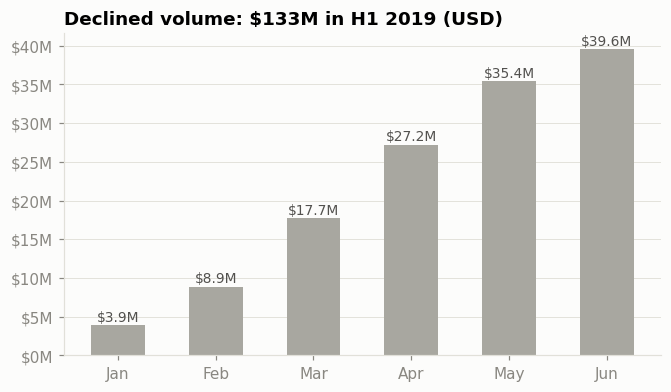

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(m.index.strftime('%b'), m.declined_usd / 1e6, color=GREY, width=.55)
label_bars(ax, bars, lambda v: f'${v:.1f}M', pad=.5, fontsize=9)
ax.yaxis.set_major_formatter(USD_M); ax.grid(axis='x', visible=False)
ax.set_title(f'Declined volume: ${dec.amount_usd.sum()/1e6:.0f}M in H1 2019 (USD)')
save('01_declined_usd_by_month')

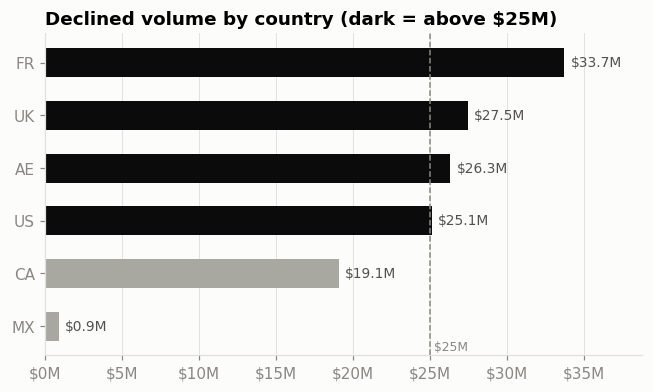

,declined_usd_m
country,
FR,33.74
UK,27.49
AE,26.34
US,25.13
CA,19.11
MX,0.88


In [ ]:
c = dec.groupby('country').amount_usd.sum().div(1e6).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(c.index, c.values, color=[DARK if v > 25 else GREY for v in c.values], height=.55)
label_bars(ax, bars, lambda v: f'${v:.1f}M', horizontal=True, pad=.4, fontsize=9)
ax.axvline(25, color=MUTED, lw=1, ls='--'); ax.text(25.3, -.45, '$25M', color=MUTED, fontsize=8)
ax.xaxis.set_major_formatter(USD_M); ax.grid(axis='y', visible=False); ax.set_xlim(0, c.max() * 1.15)
ax.set_title('Declined volume by country (dark = above $25M)')
save('02_declined_usd_by_country')
c.sort_values(ascending=False).round(2).to_frame('declined_usd_m')

## 4. Acceptance rate and root-cause cuts

Overall acceptance: 69.2%


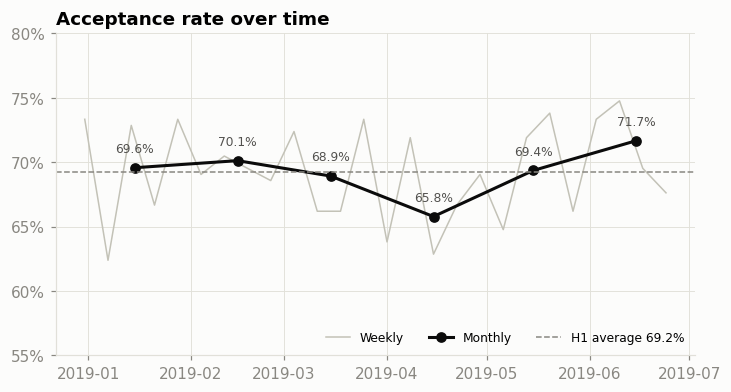

In [ ]:
print(f'Overall acceptance: {overall:.1%}')
mid = m.index + pd.Timedelta(days=14)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(acc.groupby('week').accepted.mean(), color='#c3c2b7', lw=1, label='Weekly')
ax.plot(mid, m.acc_rate, color=DARK, lw=2, marker='o', ms=6, label='Monthly')
ax.axhline(overall, color=MUTED, lw=1, ls='--', label=f'H1 average {overall:.1%}')
for t, v in zip(mid, m.acc_rate):
    ax.text(t, v + .012, f'{v:.1%}', ha='center', fontsize=8, color=INK2)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(.55, .80)
ax.legend(frameon=False, loc='lower right', ncol=3, fontsize=8)
ax.set_title('Acceptance rate over time')
save('03_acceptance_rate_over_time')

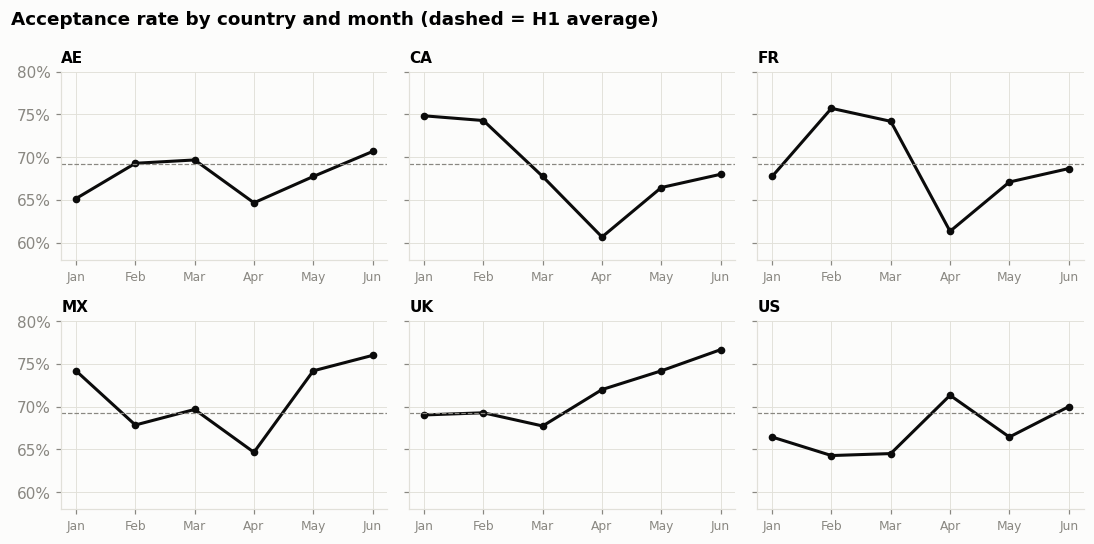

country,AE,CA,FR,MX,UK,US
month,,,,,,
2019-01-01,65.2,74.8,67.7,74.2,69.0,66.5
2019-02-01,69.3,74.3,75.7,67.9,69.3,64.3
2019-03-01,69.7,67.7,74.2,69.7,67.7,64.5
2019-04-01,64.7,60.7,61.3,64.7,72.0,71.3
2019-05-01,67.7,66.5,67.1,74.2,74.2,66.5
2019-06-01,70.7,68.0,68.7,76.0,76.7,70.0


In [ ]:
cm = acc.pivot_table(index='month', columns='country', values='accepted', aggfunc='mean')
fig, axs = plt.subplots(2, 3, figsize=(10, 5), sharey=True)
for ax, cty in zip(axs.flat, cm.columns):
    ax.plot(cm.index.strftime('%b'), cm[cty], color=DARK, lw=2, marker='o', ms=4)
    ax.axhline(overall, color=MUTED, lw=.8, ls='--')
    ax.set_title(cty, fontsize=10); ax.yaxis.set_major_formatter(PCT); ax.set_ylim(.58, .80)
    ax.tick_params(axis='x', labelsize=8)
fig.suptitle('Acceptance rate by country and month (dashed = H1 average)', x=.01, ha='left', fontweight='bold', fontsize=12)
fig.tight_layout()
save('04_acceptance_by_country_month')
(cm * 100).round(1)

In [ ]:
cm['ALL'] = m.acc_rate
april = pd.Timestamp('2019-04-01')
print('April vs mean of other months (pp):')
print(((cm.loc[april] - cm.drop(index=april).mean()) * 100).round(1).sort_values().to_string())
acc.pivot_table(index='month', columns='country', values='accepted', aggfunc='size')   # mix check

April vs mean of other months (pp):
country
CA    -9.6
FR    -9.3
MX    -7.7
ALL   -4.1
AE    -3.8
UK     0.6
US     5.0


country,AE,CA,FR,MX,UK,US
month,,,,,,
2019-01-01,155,155,155,155,155,155
2019-02-01,140,140,140,140,140,140
2019-03-01,155,155,155,155,155,155
2019-04-01,150,150,150,150,150,150
2019-05-01,155,155,155,155,155,155
2019-06-01,150,150,150,150,150,150


H1: non-USD 70.1% vs USD 67.5% (diff +2.6pp, p = 0.053)
April vs other months, Non-USD (CA, FR, UK, MX): -6.5pp (p = 0.002)
April vs other months, USD (US, AE): +0.6pp (p = 0.844)


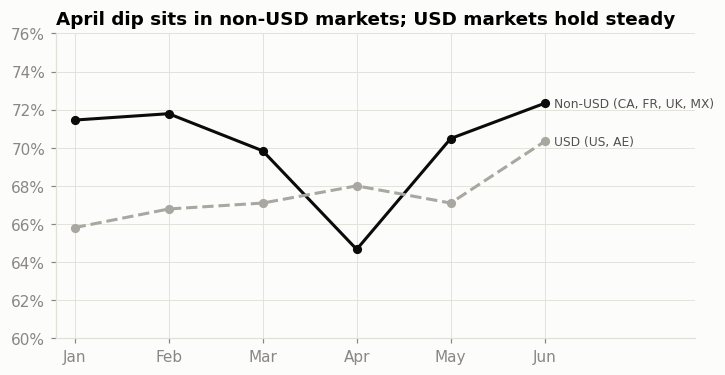

ccy_group,"Non-USD (CA, FR, UK, MX)","USD (US, AE)"
month,,
2019-01-01,71.5,65.8
2019-02-01,71.8,66.8
2019-03-01,69.8,67.1
2019-04-01,64.7,68.0
2019-05-01,70.5,67.1
2019-06-01,72.3,70.3


In [ ]:
acc['ccy_group'] = acc.currency.eq('USD').map({True: 'USD (US, AE)', False: 'Non-USD (CA, FR, UK, MX)'})
grp = acc.pivot_table(index='month', columns='ccy_group', values='accepted', aggfunc='mean')
usd = acc.currency.eq('USD')
d, pv = ztest(acc.accepted[~usd], acc.accepted[usd])
print(f'H1: non-USD {acc.accepted[~usd].mean():.1%} vs USD {acc.accepted[usd].mean():.1%} (diff {d*100:+.1f}pp, p = {pv:.3f})')
for g in grp.columns:
    a_m = acc[(acc.ccy_group == g)]
    d, pv = ztest(a_m.accepted[a_m.month == april], a_m.accepted[a_m.month != april])
    print(f'April vs other months, {g}: {d*100:+.1f}pp (p = {pv:.3f})')

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for g, style in zip(grp.columns, [dict(color=DARK, lw=2), dict(color=GREY, lw=2, ls='--')]):
    ax.plot(grp.index.strftime('%b'), grp[g], marker='o', ms=5, **style)
    ax.text(5.1, grp[g].iloc[-1], g, fontsize=8, va='center', color=INK2)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(.6, .76); ax.set_xlim(-.2, 6.6)
ax.set_title('April dip sits in non-USD markets; USD markets hold steady')
save('12_acceptance_usd_vs_non_usd')
(grp * 100).round(1)

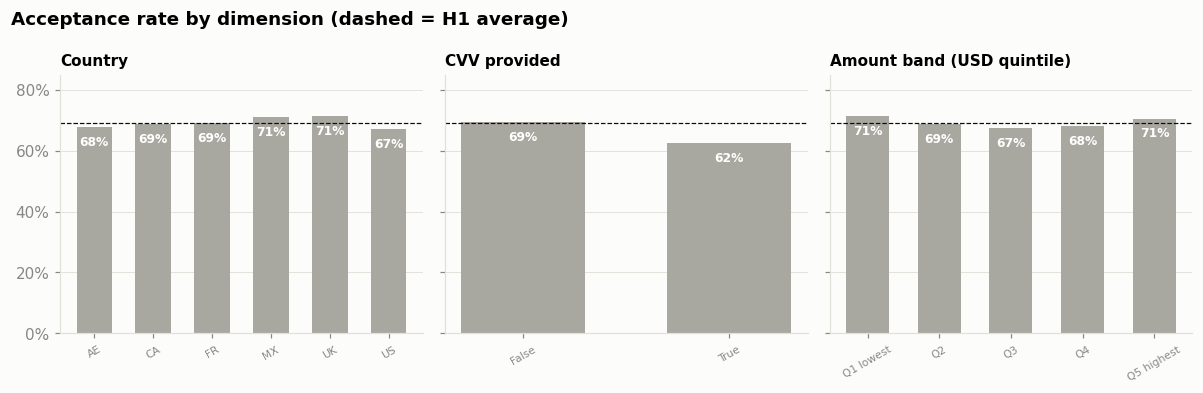

txns  acceptance  declined_usd_m
cut          value                                       
country      AE           905       0.678          26.335
             CA           905       0.686          19.108
             FR           905       0.691          33.738
             MX           905       0.712           0.876
             UK           905       0.715          27.489
             US           905       0.672          25.126
currency     CAD          905       0.686          19.108
             EUR          905       0.691          33.738
             GBP          905       0.715          27.489
             MXN          905       0.712           0.876
             USD         1810       0.675          51.461
cvv_provided False       5390       0.693         130.250
             True          40       0.625           2.423
usd_band     Q1 lowest   1086       0.715           1.082
             Q2          1086       0.687           8.858
             Q3          1086       0.675          24.447
             Q4          1086       0.680          39.672
             Q5 highest  1086       0.705          58.614

In [ ]:
acc['usd_band'] = pd.qcut(acc.amount_usd, 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])
dims = {'country': 'Country', 'currency': 'Currency', 'cvv_provided': 'CVV provided', 'usd_band': 'Amount band (USD quintile)'}
cuts = pd.concat({col: acc.groupby(col, observed=True).agg(txns=('accepted', 'size'), acceptance=('accepted', 'mean'),
                                                           declined_usd_m=('declined_usd', lambda s: s.sum() / 1e6))
                  for col in dims}, names=['cut', 'value'])

fig, axs = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, col in zip(axs, ['country', 'cvv_provided', 'usd_band']):
    g = cuts.loc[col, 'acceptance']
    bars = ax.bar(g.index.astype(str), g.values, color=GREY, width=.6)
    label_bars(ax, bars, lambda v: f'{v:.0%}', pad=-.06, color='#ffffff', fontweight='bold')
    ax.axhline(overall, color=DARK, lw=.8, ls='--')
    ax.set_title(dims[col], fontsize=10); ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, .85)
    ax.grid(axis='x', visible=False); ax.tick_params(axis='x', labelsize=7, rotation=30)
fig.suptitle('Acceptance rate by dimension (dashed = H1 average)', x=.01, ha='left', fontweight='bold', fontsize=12)
fig.tight_layout()
save('05_acceptance_by_dimension')
cuts.round(3)

In [ ]:
# Is any difference more than noise? Two-proportion z-tests: segment vs rest
segments = {f'country={c}': acc.country == c for c in sorted(acc.country.unique())}
segments |= {'cvv_provided=True': acc.cvv_provided, 'month=April': acc.month == april}
pd.DataFrame([(name, *ztest(acc.accepted[mask], acc.accepted[~mask])) for name, mask in segments.items()],
             columns=['segment', 'diff_vs_rest', 'p_value']).assign(diff_vs_rest=lambda d: d.diff_vs_rest * 100).round(3)

,segment,diff_vs_rest,p_value
0,country=AE,-1.657,0.324
1,country=CA,-0.729,0.664
2,country=FR,-0.199,0.906
3,country=MX,2.320,0.167
4,country=UK,2.718,0.106
5,country=US,-2.453,0.144
6,cvv_provided=True,-6.776,0.355
7,month=April,-4.134,0.014


## 5. Why does declined USD grow?

In [ ]:
jan_fx = acc[acc.month == acc.month.min()].groupby('currency').fx.mean()
acc['amount_usd_janfx'] = acc.amount / acc.currency.map(jan_fx)
dm = acc[~acc.accepted].groupby('month').agg(declined_n=('amount_usd', 'size'), avg_declined_usd=('amount_usd', 'mean'),
                                             declined_usd=('amount_usd', 'sum'), declined_usd_janfx=('amount_usd_janfx', 'sum'),
                                             avg_local_declined=('amount', 'mean'))
dm['fx_uplift'] = dm.declined_usd / dm.declined_usd_janfx - 1
g = dm.iloc[-1] / dm.iloc[0]
print(f'Jan->Jun growth: declined count x{g.declined_n:.2f}, avg declined ticket (USD) x{g.avg_declined_usd:.1f}, '
      f'declined USD x{g.declined_usd:.1f}, with FX held at Jan rates x{g.declined_usd_janfx:.1f}')
fx = acc.groupby(['month', 'currency']).fx.mean().unstack()
fxi = (fx.iloc[0] / fx) * 100   # USD value of 1 unit of local currency, Jan = 100
display(dm.assign(declined_usd=dm.declined_usd / 1e6, declined_usd_janfx=dm.declined_usd_janfx / 1e6).round(3))
fxi.round(1)

Jan->Jun growth: declined count x0.90, avg declined ticket (USD) x11.4, declined USD x10.3, with FX held at Jan rates x9.2


,declined_n,avg_declined_usd,declined_usd,declined_usd_janfx,avg_local_declined,fx_uplift
month,,,,,,
2019-01-01,283,13643.647,3.861,3.855,15391.131,0.002
2019-02-01,251,35398.188,8.885,8.814,42736.896,0.008
2019-03-01,289,61187.278,17.683,17.191,71615.079,0.029
2019-04-01,308,88431.760,27.237,25.598,100645.620,0.064
2019-05-01,285,124189.499,35.394,32.176,130458.811,0.100
2019-06-01,255,155343.416,39.613,35.647,161597.281,0.111


currency,CAD,EUR,GBP,MXN,USD
month,,,,,
2019-01-01,100.0,100.0,100.0,100.0,100.0
2019-02-01,101.0,101.4,100.7,100.0,100.0
2019-03-01,100.0,105.4,107.3,100.0,100.0
2019-04-01,102.6,111.9,115.9,100.1,100.0
2019-05-01,102.4,122.3,123.5,100.1,100.0
2019-06-01,103.7,128.5,119.7,100.1,100.0


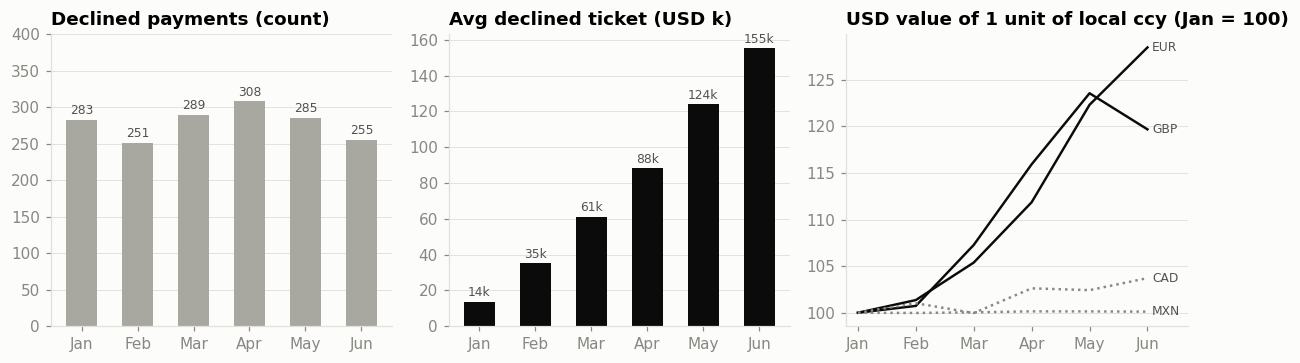

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
mo = dm.index.strftime('%b')
label_bars(axs[0], axs[0].bar(mo, dm.declined_n, color=GREY, width=.55), lambda v: f'{v:.0f}', pad=8)
label_bars(axs[1], axs[1].bar(mo, dm.avg_declined_usd / 1e3, color=DARK, width=.55), lambda v: f'{v:.0f}k', pad=3)
axs[0].set_title('Declined payments (count)'); axs[0].set_ylim(0, 400)
axs[1].set_title('Avg declined ticket (USD k)')
for cur in ['EUR', 'GBP', 'CAD', 'MXN']:
    hi = cur in ('EUR', 'GBP')
    axs[2].plot(mo, fxi[cur].values, color=DARK if hi else MUTED, lw=1.6, ls='-' if hi else ':')
    axs[2].text(5.08, fxi[cur].iloc[-1], cur, fontsize=8, va='center', color=INK2)
axs[2].set_title('USD value of 1 unit of local ccy (Jan = 100)'); axs[2].set_xlim(-.2, 5.7)
for ax in axs:
    ax.grid(axis='x', visible=False)
fig.tight_layout()
save('08_volume_vs_ticket_vs_fx')

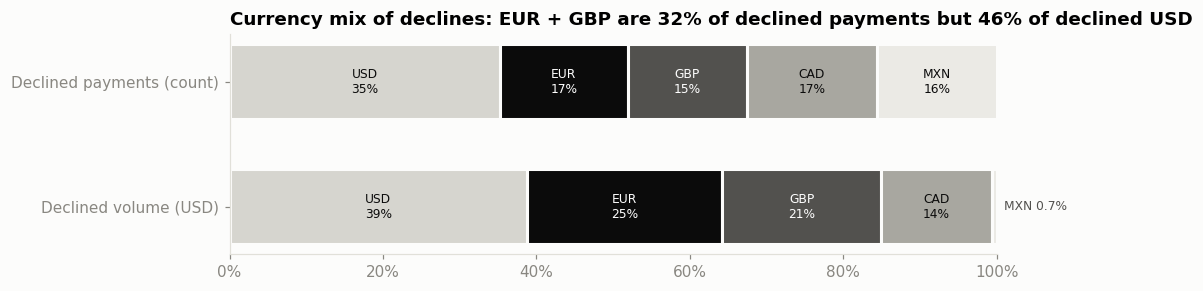

,Declined payments (count),Declined volume (USD)
currency,,
USD,35.2,38.8
EUR,16.8,25.4
GBP,15.4,20.7
CAD,17.0,14.4
MXN,15.6,0.7


In [ ]:
order = ['USD', 'EUR', 'GBP', 'CAD', 'MXN']
share = pd.DataFrame({'Declined payments (count)': dec.currency.value_counts(normalize=True),
                      'Declined volume (USD)': dec.groupby('currency').amount_usd.sum() / dec.amount_usd.sum()}).loc[order]
shades = {'USD': '#d6d5cf', 'EUR': DARK, 'GBP': INK2, 'CAD': GREY, 'MXN': '#ebeae5'}
fig, ax = plt.subplots(figsize=(9, 2.6))
for row, col in enumerate(share):
    left = share[col].cumsum() - share[col]
    ax.barh(row, share[col], left=left, color=[shades[c] for c in order], edgecolor='#fcfcfb', linewidth=2, height=.6)
    for cur in order:
        v = share.loc[cur, col]
        if v > .04:
            ax.text(left[cur] + v / 2, row, f'{cur}\n{v:.0%}', ha='center', va='center', fontsize=8,
                    color='#ffffff' if cur in ('EUR', 'GBP') else DARK)
ax.text(1.01, 1, f"MXN {share.loc['MXN', 'Declined volume (USD)']:.1%}", va='center', fontsize=8, color=INK2)
ax.set_yticks([0, 1]); ax.set_yticklabels(share.columns); ax.invert_yaxis()
ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1); ax.grid(False)
ax.set_title('Currency mix of declines: EUR + GBP are 32% of declined payments but 46% of declined USD')
save('10_declined_currency_mix')
(share * 100).round(1)

In [ ]:
acc.groupby('currency').agg(avg_local_amount=('amount', 'mean'), avg_usd_amount=('amount_usd', 'mean'),
                            fx_per_usd=('fx', 'mean')).round(2).sort_values('avg_usd_amount', ascending=False)

,avg_local_amount,avg_usd_amount,fx_per_usd
currency,,,
EUR,88534.45,116670.10,0.81
GBP,81141.00,113682.56,0.75
USD,89036.49,89036.49,1.00
CAD,88268.49,63598.18,1.40
MXN,85614.71,3414.31,25.08


In [ ]:
def corr_p(x, y):
    ok = x.notna() & y.notna(); r = x[ok].corr(y[ok]); n = ok.sum()
    t = r * sqrt((n - 2) / (1 - r * r)); return r, 2 * (1 - .5 * (1 + erf(abs(t) / sqrt(2))))
rows = []
for cur in ['EUR', 'GBP', 'CAD', 'MXN']:
    w = acc[acc.currency == cur].groupby('week').agg(acceptance=('accepted', 'mean'), fx=('fx', 'mean'))
    rows.append((cur, *corr_p(w.acceptance, w.fx), *corr_p(w.acceptance, w.fx.pct_change())))
pd.DataFrame(rows, columns=['currency', 'r_level', 'p_level', 'r_weekly_change', 'p_weekly_change']).round(2)

,currency,r_level,p_level,r_weekly_change,p_weekly_change
0,EUR,0.18,0.37,0.19,0.34
1,GBP,-0.34,0.07,0.21,0.31
2,CAD,0.30,0.13,0.16,0.45
3,MXN,-0.05,0.81,-0.14,0.48


Correlation, within-month amount rank vs accepted: r = -0.005, p = 0.74
Top 10% largest payments accepted: 69.4% vs bottom half 69.3%

state       ACCEPTED  DECLINED
month                         
2019-01-01   11804.0   12873.0
2019-02-01   39049.0   37910.0
2019-03-01   70341.0   69930.0
2019-04-01  104258.0  102572.0
2019-05-01  132338.0  133350.0
2019-06-01  163817.0  167216.0


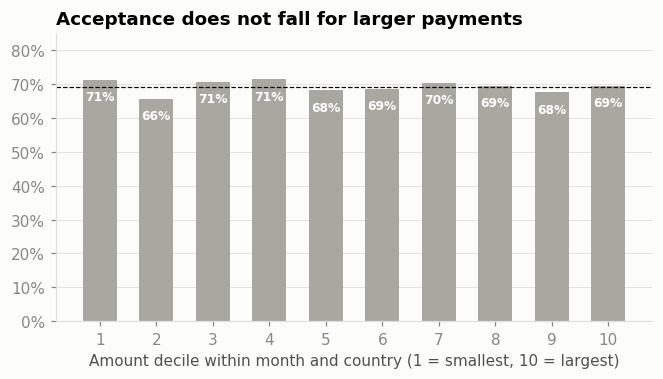

In [ ]:
acc['amount_rank'] = acc.groupby(['month', 'country']).amount.rank(pct=True)
acc['rank_decile'] = (acc.amount_rank * 10).clip(upper=9.999).astype(int) + 1
r = acc.amount_rank.corr(acc.accepted.astype(float))
t = r * sqrt((len(acc) - 2) / (1 - r * r))
print(f'Correlation, within-month amount rank vs accepted: r = {r:.3f}, p = {2 * (1 - .5 * (1 + erf(abs(t) / sqrt(2)))):.2f}')
top = acc.amount_rank > .9
print(f'Top 10% largest payments accepted: {acc.accepted[top].mean():.1%} vs bottom half {acc.accepted[acc.amount_rank <= .5].mean():.1%}')
print(); print(acc.pivot_table(index='month', columns='state', values='amount_usd', aggfunc='median').round(0))

dd = acc.groupby('rank_decile').accepted.mean()
fig, ax = plt.subplots(figsize=(7, 3.4))
bars = ax.bar(dd.index.astype(str), dd.values, color=GREY, width=.6)
label_bars(ax, bars, lambda v: f'{v:.0%}', pad=-.06, color='#ffffff', fontweight='bold')
ax.axhline(overall, color=DARK, lw=.8, ls='--')
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, .85); ax.grid(axis='x', visible=False)
ax.set_xlabel('Amount decile within month and country (1 = smallest, 10 = largest)')
ax.set_title('Acceptance does not fall for larger payments')
save('11_acceptance_by_amount_decile')

## 6. Chargebacks

In [ ]:
# validate='one_to_one' raises if either side has duplicate keys (which would silently duplicate payments)
j = acc.merge(cb[['external_ref', 'chargeback']], on='external_ref', how='left', validate='one_to_one')
assert len(j) == len(acc), 'Join changed the number of payments'
print(pd.crosstab(j.state, j.chargeback, margins=True))
early = j[j.accepted & (j.date_time < '2019-01-21')]
late = j[j.accepted & (j.date_time >= '2019-01-21')]
print(f'\nAccepted payments 1-20 Jan:        {early.chargeback.sum()} of {len(early)} flagged = {early.chargeback.mean():.1%}')
print(f'Accepted payments 21 Jan - 30 Jun: {late.chargeback.sum()} of {len(late)} flagged = {late.chargeback.mean():.1%}')
print(f'Avg amount, 1-20 Jan: flagged ${early[early.chargeback].amount.mean():,.0f} vs not flagged ${early[~early.chargeback].amount.mean():,.0f}')

chargeback  False  True   All
state                        
ACCEPTED     3536   223  3759
DECLINED     1671     0  1671
All          5207   223  5430

Accepted payments 1-20 Jan:        223 of 416 flagged = 53.6%
Accepted payments 21 Jan - 30 Jun: 0 of 3343 flagged = 0.0%
Avg amount, 1-20 Jan: flagged $8,012 vs not flagged $13,411


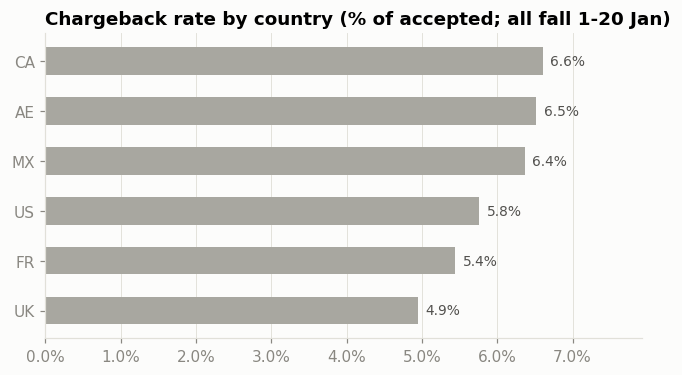

In [ ]:
g = j[j.accepted].groupby('country').chargeback.mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(g.index, g.values, color=GREY, height=.55)
label_bars(ax, bars, lambda v: f'{v:.1%}', horizontal=True, pad=.001, fontsize=9)
ax.xaxis.set_major_formatter(mt.PercentFormatter(1.0, decimals=1)); ax.grid(axis='y', visible=False); ax.set_xlim(0, g.max() * 1.2)
ax.set_title('Chargeback rate by country (% of accepted; all fall 1-20 Jan)')
save('06_chargeback_rate_by_country')

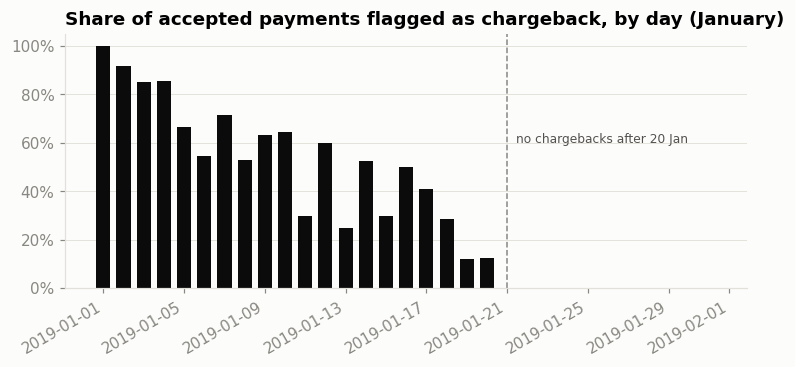

In [ ]:
daily = j[j.accepted & (j.date_time < '2019-02-01')].groupby(j.date_time.dt.floor('D')).chargeback.mean()
cut_off = pd.Timestamp('2019-01-21')
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(daily.index, daily.values, color=[DARK if d < cut_off else GREY for d in daily.index], width=.7)
ax.axvline(cut_off, color=MUTED, ls='--', lw=1)
ax.text(cut_off + pd.Timedelta(hours=10), .6, 'no chargebacks after 20 Jan', fontsize=8, color=INK2)
ax.yaxis.set_major_formatter(PCT); ax.grid(axis='x', visible=False); fig.autofmt_xdate()
ax.set_title('Share of accepted payments flagged as chargeback, by day (January)')
save('09_chargeback_share_by_day')